In [1]:
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
import pendulum as pdl

In [2]:
files = glob.glob('utilization/*.csv')

utilization_df = pd.DataFrame()
for file in files:
    df = pd.read_csv(file)
    print(f"File: {file}")
    print(df.head())
    print("\n")
    utilization_df = pd.concat([utilization_df, df], ignore_index=True)

print("Final DataFrame:")
print(utilization_df)
utilization_df.head()

File: utilization/log_ts01.csv
                    timestamp machine_name          machine_os  cpu_percent  \
0  2026-10-16 14:38:47.598271         ts01  Windows 2019Server        100.0   
1  2026-10-16 14:39:10.659698         ts01  Windows 2019Server        100.0   
2  2026-10-16 14:39:33.726114         ts01  Windows 2019Server        100.0   
3  2026-10-16 14:39:56.794024         ts01  Windows 2019Server        100.0   
4  2026-10-16 14:40:19.858797         ts01  Windows 2019Server        100.0   

   cpu_count  memory_total_GB  memory_used_GB  memory_available_GB  \
0         16       127.999062       95.447220            32.551842   
1         16       127.999062       95.556583            32.442478   
2         16       127.999062       95.534378            32.464684   
3         16       127.999062       95.541035            32.458027   
4         16       127.999062       95.530487            32.468575   

   memory_percent  disk_total_GB  disk_used_GB  disk_free_GB  disk_percen

,timestamp,machine_name,machine_os,cpu_percent,cpu_count,memory_total_GB,memory_used_GB,memory_available_GB,memory_percent,disk_total_GB,disk_used_GB,disk_free_GB,disk_percent,net_bytes_sent_MB,net_bytes_recv_MB,uptime_hours,Unnamed: 16
0,2026-10-16 14:38:47.598271,ts01,Windows 2019Server,100.0,16,127.999062,95.447220,32.551842,74.6,2047.397457,729.871574,1317.525883,35.6,1.879463e+06,2.087885e+06,4054.523755,NaN
1,2026-10-16 14:39:10.659698,ts01,Windows 2019Server,100.0,16,127.999062,95.556583,32.442478,74.7,2047.397457,729.884396,1317.513062,35.6,1.879464e+06,2.087886e+06,4054.530161,NaN
2,2026-10-16 14:39:33.726114,ts01,Windows 2019Server,100.0,16,127.999062,95.534378,32.464684,74.6,2047.397457,729.884544,1317.512913,35.6,1.879464e+06,2.087886e+06,4054.536568,NaN
3,2026-10-16 14:39:56.794024,ts01,Windows 2019Server,100.0,16,127.999062,95.541035,32.458027,74.6,2047.397457,729.889339,1317.508118,35.6,1.879464e+06,2.087887e+06,4054.542976,NaN
4,2026-10-16 14:40:19.858797,ts01,Windows 2019Server,100.0,16,127.999062,95.530487,32.468575,74.6,2047.397457,729.901424,1317.496033,35.7,1.879465e+06,2.087893e+06,4054.549383,NaN


machine_name
IMB-ANSYS-HPC    [Axes(0.125,0.11;0.775x0.77)]
ts01             [Axes(0.125,0.11;0.775x0.77)]
ts02             [Axes(0.125,0.11;0.775x0.77)]
ts04             [Axes(0.125,0.11;0.775x0.77)]
dtype: object

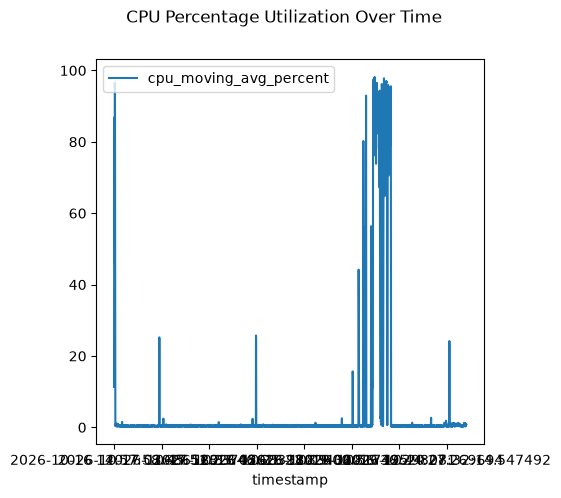

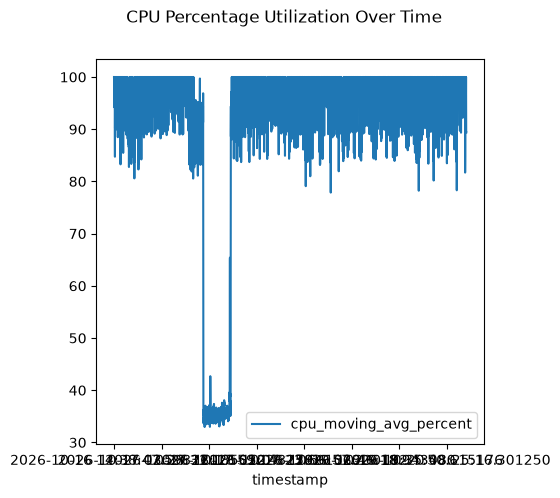

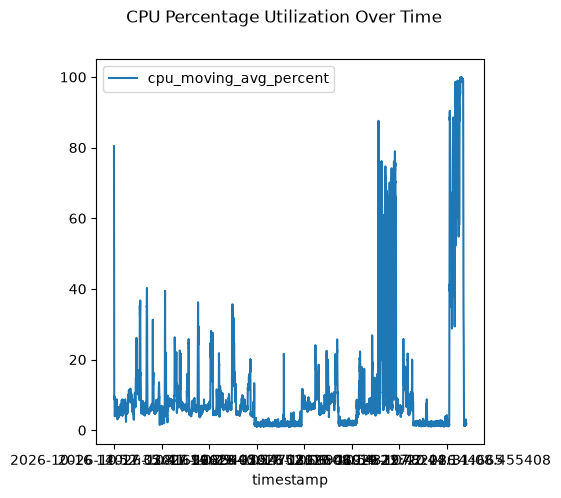

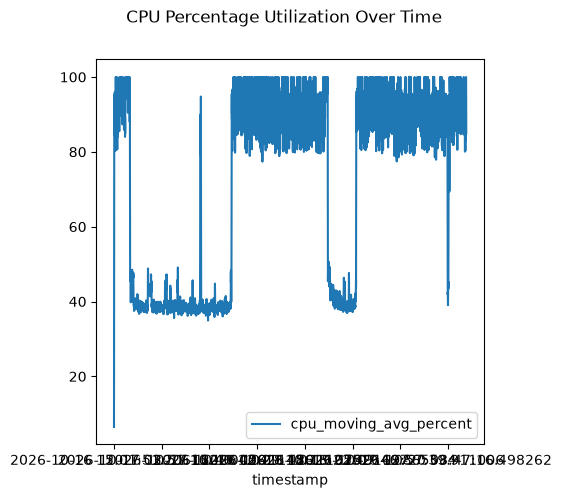

In [3]:
# calculate moving average for cpu_percent
window = 50 # * 20 to seconds
utilization_df['cpu_moving_avg_percent'] = utilization_df['cpu_percent'].transform(lambda x: x.rolling(window=10, min_periods=1).mean())
# plot the utilization over time, split by a machine_name
grouped = utilization_df.groupby('machine_name')

# def plot_utilization(grouped, type_: str = 'cpu_moving_avg_percent'):
#         # CPU Percentage Utilization
#         grouped.plot(x='timestamp', y=type, title='CPU Percentage Utilization Over Time', subplots=True, layout=(len(grouped), 1), figsize=(10, 5*len(grouped)))





grouped.plot(x='timestamp', y='cpu_moving_avg_percent', title='CPU Percentage Utilization Over Time', subplots=True, 
             sharex=True, figsize=(5,5))
\
# plot_utilization(grouped, type_='cpu_moving_avg_percent')

In [4]:
# compute hourly average of desired utilization metric (e.g., cpu_percent) for each machine
utilization_df['timestamp'] = pd.to_datetime(utilization_df['timestamp'])
def compute_hourly_average(df, metric='cpu_percent'):
    # Convert timestamp to datetime if it's not already
    df = df.copy()
    df.set_index('timestamp', inplace=True)
    
    # Resample to hourly intervals and compute mean for the specified metric
    hourly_avg = df.groupby('machine_name').resample('h')[metric].mean().reset_index()
    return hourly_avg   

hourly_cpu_avg = compute_hourly_average(utilization_df, metric='cpu_percent')
hourly_mem_avg = compute_hourly_average(utilization_df, metric='memory_percent')

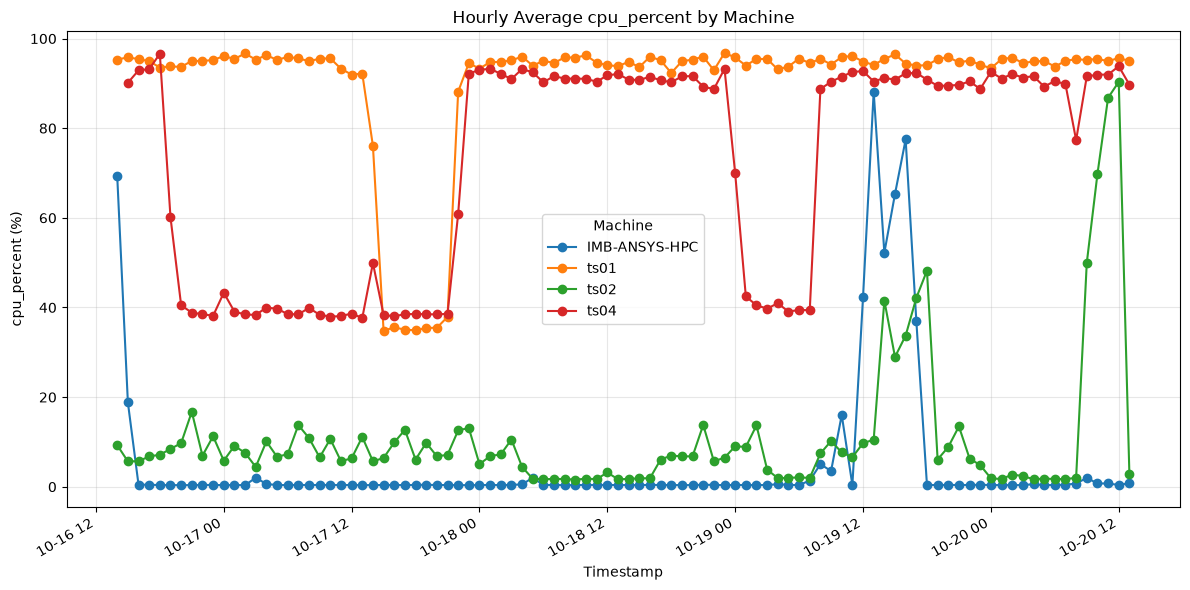

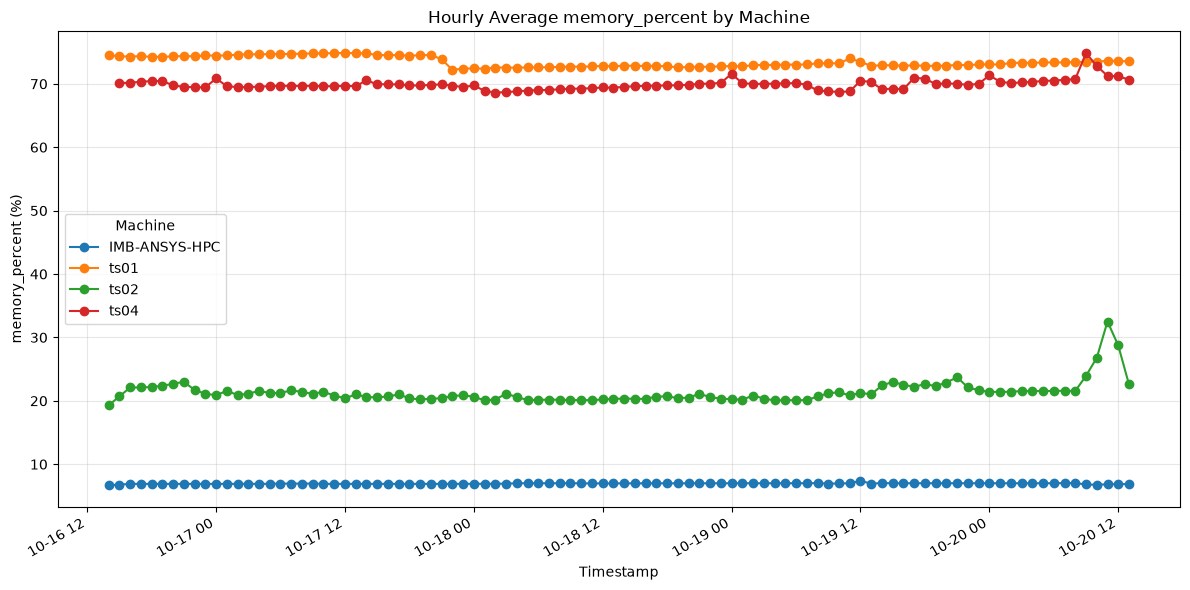

In [5]:
subplots = False  # False = all machines on one plot; True = separate subplots

def plot_data(df, subplots=False):
    machines = df["machine_name"].unique()
    metric = df.columns[2]  # Assuming the metric is the third column (after timestamp and machine_name)
    if subplots:
        # Separate subplot for each machine
        fig, axes = plt.subplots(
            len(machines), 1,
            figsize=(10, 5 * len(machines)),
            sharex=True,
            squeeze=False,
        )

        for ax, machine in zip(axes.flatten(), machines):
            group = df[df["machine_name"] == machine]

            ax.plot(
                group["timestamp"],
                group["cpu_percent"],
                marker="o",
                label=machine,
            )

            ax.set_title(f"CPU Utilization - {machine}")
            ax.set_ylabel("CPU Utilization (%)")
            ax.set_yscale("log")
            ax.legend()
            ax.grid(True, alpha=0.3)

        axes[-1, 0].set_xlabel("Timestamp")

    else:
        # All machines on the same plot, with different colors
        fig, ax = plt.subplots(figsize=(12, 6))

        for machine, group in df.groupby("machine_name"):
            ax.plot(
                group["timestamp"],
                group[metric],
                marker="o",
                label=machine,
            )

        ax.set_title(f"Hourly Average {metric} by Machine")
        ax.set_xlabel("Timestamp")
        ax.set_ylabel(f"{metric} (%)")
        ax.legend(title="Machine")
        ax.grid(True, alpha=0.3)

    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()



plot_data(hourly_cpu_avg, subplots=subplots)
plot_data(hourly_mem_avg, subplots=subplots)